In [1]:
import numpy as np
np.set_printoptions(threshold=np.inf)
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import normflows as nf
import random
from torch.utils.data import DataLoader
import pandas as pd
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
import pyvinecopulib as pv

from scipy.stats import norm

from GPDFlow_S import S_mGPD_NF, ConditionalMaskedAffineFlow, ActNormConditional, ConditionalNormalizingFlow
import Common_Functions as cf
from matplotlib.colors import LinearSegmentedColormap
import scipy.stats as stats


Using device: cuda


#### Define a GPDFlow

In [2]:
dir_out = "/home/pgrad2/2448355h/My_PhD_Project/GPDFlow/Data_and_Model/"

dim = 20


#### Find a suitable threshold for the simulated data

In [3]:
from scipy.stats import burr12

np.random.seed(42)
n_samples = 10000

# ── Burr XII marginal parameters ──────────────────────────────────────────────
# Burr XII CDF: F(x) = 1 - (1 + x^c)^{-k},  x > 0
# Tail index α = c*k  →  GPD shape γ ≈ 1/(c*k)
c_base = np.array([2.0, 3.0, 2.5, 1.5, 3.0])
k_base = np.array([1.5, 1.0, 2.0, 3.0, 3.5])
c_vals = np.tile(c_base, dim // len(c_base) + 1)[:dim]
k_vals = np.tile(k_base, dim // len(k_base) + 1)[:dim]

# ── One-factor Gumbel copula ─────────────────────────────────────────────────
# Latent V ~ U(0,1); each U_j is linked to V by its own bivariate Gumbel copula
# C_j(U_j, V; theta_j), so U_j | V is drawn through the Gumbel h-inverse.
# Joint copula:  C(u) = ∫_0^1 ∏_j F_{U_j|V}(u_j | v) dv.
# theta_j = 1 + s_j with s_j spaced evenly in the OPEN interval (0, 7), so
# theta_j in (1, 8): theta = 1 is independence, larger theta = stronger
# upper-tail dependence (chi_link = 2 - 2**(1/theta)).  The x7 scale spreads the
# induced pairwise chi across ~0.2-0.86 (theta in (1, 2) bunched it into
# 0.02-0.41).  Pair dependence is a function of (theta_i, theta_j), not lag.
theta = 1.0 + np.linspace(0, 7.0, dim + 2)[1:-1]        # (dim,) in (1, 8)

def simulate_factor_copula(n, thetas, seed=42):
    rng = np.random.default_rng(seed)
    V = rng.random(n)
    U = np.empty((n, len(thetas)))
    for j, th in enumerate(thetas):
        bicop = pv.Bicop(pv.BicopFamily.gumbel, parameters=np.array([[th]]))
        U[:, j] = bicop.hinv1(np.column_stack([V, rng.random(n)]))   # U_j | V
    return U                                            # shape (n, d), uniform

U = simulate_factor_copula(n_samples, theta, seed=42)

# Apply Burr XII marginals via inverse CDF
samples_origin = np.column_stack([
    burr12.ppf(U[:, j], c=c_vals[j], d=k_vals[j]) for j in range(dim)
])
print(f"Generated {n_samples} samples  |  shape: {samples_origin.shape}")

# ── True GPD parameters at the 96th-percentile threshold (fitted on large sample) ──
# For Burr XII the excess above a high threshold converges to a GPD;
# we obtain the limiting (σ, γ) numerically from a large independent Burr sample.
thres_q = 0.96
n_fit   = 200_000
true_sigma, true_gamma = [], []
for j in range(dim):
    big = burr12.rvs(c=c_vals[j], d=k_vals[j], size=n_fit, random_state=j)
    u_j = burr12.ppf(thres_q, c=c_vals[j], d=k_vals[j])
    exc = big[big > u_j] - u_j
    g, _, s = stats.genpareto.fit(exc, floc=0)
    true_gamma.append(g)
    true_sigma.append(s)

sigma = torch.tensor(true_sigma, dtype=torch.float32)
gamma = torch.tensor(true_gamma, dtype=torch.float32)
print(f"sigma = {sigma.numpy().round(3)}")
print(f"gamma = {gamma.numpy().round(3)}")

if dim == 2:
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(samples_origin[:, 0], samples_origin[:, 1], alpha=0.3, s=5, color='steelblue')
    ax.set_xlabel('$X_1$');  ax.set_ylabel('$X_2$')
    ax.set_title('One-factor Gumbel copula + Burr XII margins')
    plt.tight_layout();  plt.show()


Generated 10000 samples  |  shape: (10000, 20)


sigma = [1.01  0.971 0.423 0.519 0.18  1.019 0.983 0.42  0.53  0.17  1.026 0.986
 0.432 0.504 0.177 1.025 1.014 0.436 0.53  0.178]
gamma = [0.335 0.321 0.177 0.186 0.026 0.33  0.335 0.196 0.161 0.066 0.316 0.337
 0.154 0.202 0.022 0.332 0.313 0.164 0.18  0.029]


In [4]:
# ── Reference pairwise chi of the one-factor Gumbel copula (large-sample MC) ──
# There is no simple closed form for the (i, j) pair chi of a one-factor Gumbel
# copula, so we take a large independent draw and use the rank-based estimator at
# a high level as the reference ("truth") for the diagnostic scatter plots below.
N_CHI_TRUTH = 2_000_000
U_chi_truth = simulate_factor_copula(N_CHI_TRUTH, theta, seed=42)
chi_theo = cf.pairwise_chi_from_data(U_chi_truth, p=0.999)     # (dim, dim), diag 1
chi_emp  = cf.pairwise_chi_from_data(samples_origin, p=0.999)

iu = np.triu_indices(dim, k=1)
chi_off = chi_theo[iu]
print(f"chi_ref off-diagonal | min {chi_off.min():.3f}  median {np.median(chi_off):.3f}  "
      f"max {chi_off.max():.3f}  sd {chi_off.std():.3f}")
print("theta_i  theta_j | chi_ref(MC) | chi_emp(q=0.99)")
order = np.argsort(chi_off)                                   # 10 pairs low -> high chi
for k in np.linspace(0, len(order) - 1, 10).astype(int):
    i, j = iu[0][order[k]], iu[1][order[k]]
    print(f"{theta[i]:6.2f}  {theta[j]:6.2f} | {chi_theo[i, j]:11.4f} | {chi_emp[i, j]:.4f}")
# chi_ref is a finite-level (q=0.99) rank estimate on 5e5 draws; the n=5000
# chi_emp sits near it up to sampling noise.


chi_ref off-diagonal | min 0.206  median 0.700  max 0.860  sd 0.169
theta_i  theta_j | chi_ref(MC) | chi_emp(q=0.99)
  1.33    1.67 |      0.2065 | 0.3000
  1.67    2.67 |      0.4250 | 0.4000
  2.00    4.00 |      0.5405 | 0.6000
  2.33    5.33 |      0.6190 | 0.8000
  3.00    4.67 |      0.6825 | 0.6000
  3.33    4.67 |      0.7235 | 0.6000
  4.00    6.00 |      0.7620 | 0.9000
  4.67    6.00 |      0.7905 | 0.8000
  5.67    7.00 |      0.8235 | 0.8000
  7.00    7.67 |      0.8600 | 0.8000


chosen q = 0.96: 1256 exceedance rows (>= 1 margin above its q-quantile)
chi  : estimate at q = 0.96: 0.1097 [0.0772, 0.1350]
omega: estimate at q = 0.96: 3.1471 [3.0074, 3.2727]


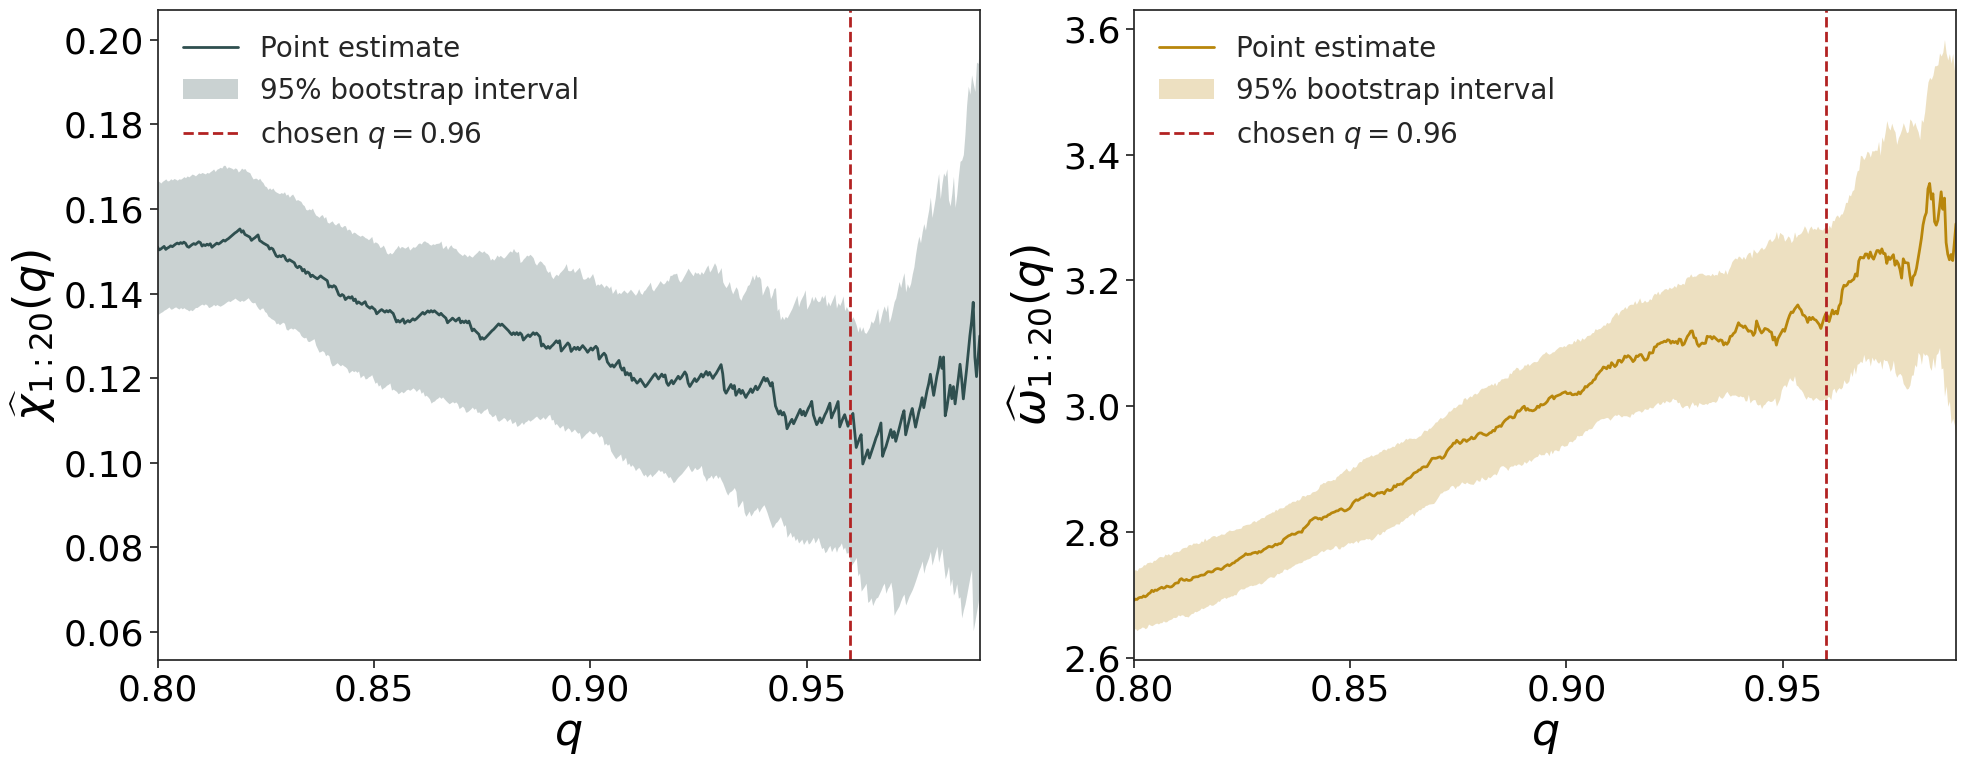

In [5]:
probs = np.linspace(0.8, 0.99, 500)
k = dim

# ── Threshold selection: chi_{1:k}(q) and omega_{1:k}(q) stability plots ──────
# Both measures depend only on ranks, so they are computed directly on the
# simulated sample.  Above a threshold where the mGPD approximation holds, the
# multivariate GPD is threshold-stable and chi(q), omega(q) should be roughly
# constant in q.  Uncertainty: nonparametric bootstrap over rows (percentile 95%).
N_BOOT   = 200
Q_CHOSEN = 0.96

def tail_dep_curves(X, probs):
    """Vectorised cf.empirical_tail_dependence_measure over all levels in probs."""
    Q   = np.quantile(X, probs, axis=0)          # (P, k)
    exc = X[None, :, :] > Q[:, None, :]          # (P, n, k)
    den = exc[:, :, 0].sum(1)
    chi = exc.all(2).sum(1) / np.maximum(den, 1)
    omg = exc.any(2).sum(1) / np.maximum(den, 1)
    return np.where(den > 0, chi, 0.), np.where(den > 0, omg, 0.)

X_one = samples_origin[:, :k]
chi_hat, omega_hat = tail_dep_curves(X_one, probs)
for i in [0, len(probs) // 2, len(probs) - 1]:   # sanity check against the scalar estimator
    assert np.isclose(chi_hat[i],   cf.empirical_tail_dependence_measure(X_one, probs[i], 'and'))
    assert np.isclose(omega_hat[i], cf.empirical_tail_dependence_measure(X_one, probs[i], 'or'))

rng_boot   = np.random.default_rng(0)
chi_boot   = np.empty((N_BOOT, len(probs)))
omega_boot = np.empty((N_BOOT, len(probs)))
for b in range(N_BOOT):
    idx = rng_boot.integers(0, len(X_one), len(X_one))
    chi_boot[b], omega_boot[b] = tail_dep_curves(X_one[idx], probs)

i_chosen = np.argmin(np.abs(probs - Q_CHOSEN))
n_clust  = np.any(X_one > np.quantile(X_one, Q_CHOSEN, axis=0), axis=1).sum()
print(f'chosen q = {Q_CHOSEN}: {n_clust} exceedance rows (>= 1 margin above its q-quantile)')
for name, hat, boot in [('chi', chi_hat, chi_boot), ('omega', omega_hat, omega_boot)]:
    lo, hi = np.quantile(boot[:, i_chosen], [0.025, 0.975])
    print(f'{name:5s}: estimate at q = {Q_CHOSEN}: {hat[i_chosen]:.4f} [{lo:.4f}, {hi:.4f}]')

# 1x2 grid: chi_{1:k}(q) (left), omega_{1:k}(q) (right)
sns.set(style="ticks", font_scale=1.5)
label_fs, tick_fs, legend_fs = 32, 26, 20

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (hat, boot, sym, color) in zip(
        axes, [(chi_hat, chi_boot, r'\chi', 'darkslategray'),
               (omega_hat, omega_boot, r'\omega', 'darkgoldenrod')]):
    lo, hi = np.quantile(boot, [0.025, 0.975], axis=0)
    ax.plot(probs, hat, color=color, linewidth=2, label='Point estimate')
    ax.fill_between(probs, lo, hi, color=color, alpha=0.25, linewidth=0,
                    label='95% bootstrap interval')
    ax.axvline(Q_CHOSEN, color='firebrick', linestyle='--', linewidth=2,
               label=rf'chosen $q = {Q_CHOSEN}$')
    ax.set_xlim(probs[0], probs[-1])
    ax.set_xlabel(r'$q$', color='black', fontsize=label_fs)
    ax.set_ylabel(rf'$\widehat{{{sym}}}_{{1:{k}}}(q)$', color='black', fontsize=label_fs)
    ax.tick_params(axis='both', labelcolor='black', labelsize=tick_fs)
    ax.legend(fontsize=legend_fs, frameon=False, loc='best')

fig.tight_layout()
plt.savefig(dir_out + 'Plots/' + 'Scenario2_threshold_selection.pdf', bbox_inches='tight')
plt.show()

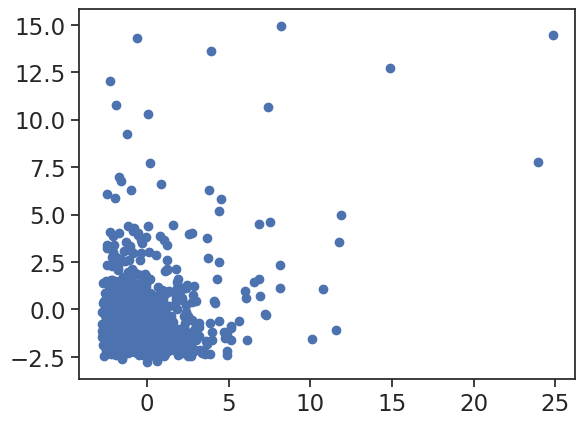

In [6]:
THRESHOLD_Q = 0.96

thres = np.quantile(samples_origin, THRESHOLD_Q, axis=0)

cond = np.any(samples_origin > thres, axis=1)
samples = samples_origin[cond,:]

thres = thres.reshape(1,-1)
samples = samples - thres

plt.scatter(samples[:,0],samples[:,1] )


In [7]:
samples.shape

(1256, 20)

In [8]:
# --- 5-fold cross-validation setup ------------------------------------------
import importlib
import cv_utils
importlib.reload(cv_utils)
from cv_utils import (
    make_folds,
    run_cv_gpdflow_likelihood,
    run_cv_gpdflow_mmd,
    run_cv_flow_baseline,
    run_cv_parametric_mgpd,
    build_probit_copula,
    cv_pairwise_chi
)

SMOKE = False                     # set True for a fast top-to-bottom check
EPOCHS_LIK = 5 if SMOKE else 500
EPOCHS_MMD = 5 if SMOKE else 500
EPOCHS_BL  = 5 if SMOKE else 500
EPOCHS_PAR = 5 if SMOKE else 500
SIM_MULT   = 50                   # simulated rows per fold = SIM_MULT * |fold k|


In [9]:
folds = make_folds(len(samples), n_splits=5, seed=1234)
print('fold val sizes:', [len(v) for _, v in folds])

fold val sizes: [252, 251, 251, 251, 251]


In [10]:
# --- Likelihood-based GPDFlow, 5-fold cross-validation ---------------------
# For fold k: train on the other 4 folds, early-stop on fold k (patience 100 on
# the validation NLL), then draw SIM_MULT * |fold k| observations from the
# fold-k model.  cv_utils keeps the 5 out-of-fold blocks SEPARATE
# (`samples_simu_folds`, raw scale) and computes NO tail-dependence summary --
# chi / omega are formed here, so the evaluation threshold can be changed
# without refitting.
THRESHOLD_Q = 0.999

dim = samples.shape[1]
p_cluster = samples.shape[0] / samples_origin.shape[0]
p_sim_q = 1.0 - (1.0 - THRESHOLD_Q) / p_cluster    # cluster-conditional level matching q = THRESHOLD_Q

# Shared flow / penalty config: used by BOTH the CV below and the final
# full-data fit, so the two can never drift.  Tuned winner for q = 0.96 from
# Data_and_Model/sim2s_nsf/best_configs.json["0.96"]["lik"] (CV RMSE chi = 0.0562).
LIK_CFG = dict(
    num_layers=2, latent_size_factor=2,
    penalty_lambda=1e4, marg_lambda=300,
    flow_type='nsf', flow_kw=dict(num_bins=7, num_blocks=1, tail_bound=5.0),
    seed=1234,
)


def cv_pairwise_chi(fold_blocks, p):
    """Mean over CV folds of each fold model's rank-based pairwise chi at level p
    (folds are NOT pooled -- a pool of 5 separately fitted flows is a mixture)."""
    return np.mean([cf.pairwise_chi_from_data(b, p=p) for b in fold_blocks], axis=0)


def cv_pairwise_omega(fold_blocks, p):
    return np.mean([cf.pairwise_omega_from_data(b, p=p) for b in fold_blocks], axis=0)


cv_like = run_cv_gpdflow_likelihood(
    samples, folds, device, thres,
    epochs=EPOCHS_LIK, samples_multiplier=SIM_MULT,
    patience=100, **LIK_CFG,
    init_from_gpd=False,          # as in the hparam sweep (driver default)
)

print('p_cluster =', round(p_cluster, 4), ' p_sim_q =', round(p_sim_q, 4))
print('per-fold best val NLL :', np.round(cv_like['best_vals'], 4))
print('per-fold best epoch   :', [h['best_epoch'] for h in cv_like['hist']])
print('fold-mean sigma_hat   :', np.round(cv_like['sigma_hat'], 3))
print('fold-mean gamma_hat   :', np.round(cv_like['gamma_hat'], 3))


[likelihood] fold 1/5 (train 1004, val 252)


  scipy margin init  gamma~[0.337 0.403 0.115 0.153 0.036 0.376 0.324 0.286 0.179 0.057 0.362 0.304
 0.187 0.198 0.014 0.28  0.399 0.146 0.204 0.052]
  scipy margin init  sigma~[1.172 0.894 0.502 0.568 0.176 1.078 1.03  0.373 0.568 0.175 0.962 1.028
 0.43  0.548 0.188 1.166 0.92  0.473 0.532 0.173]
  epoch    1/500 | train=299.6382 | val=314.0635 | val_nll=29.4233
  epoch   25/500 | train=205.3891 | val=230.4511 | val_nll=10.9553
  epoch   50/500 | train=187.4982 | val=217.2461 | val_nll=6.1370
  epoch   75/500 | train=183.8008 | val=212.6498 | val_nll=3.8101
  epoch  100/500 | train=183.9585 | val=212.3994 | val_nll=3.6691
  epoch  125/500 | train=182.3612 | val=212.4489 | val_nll=3.3882
  epoch  150/500 | train=183.1322 | val=212.0281 | val_nll=3.2442
  epoch  175/500 | train=182.4234 | val=211.5095 | val_nll=3.3594
  epoch  200/500 | train=178.3958 | val=211.8693 | val_nll=3.4285
  epoch  225/500 | train=183.2425 | val=212.3084 | val_nll=3.6507
  early stopping at epoch 246 (best va

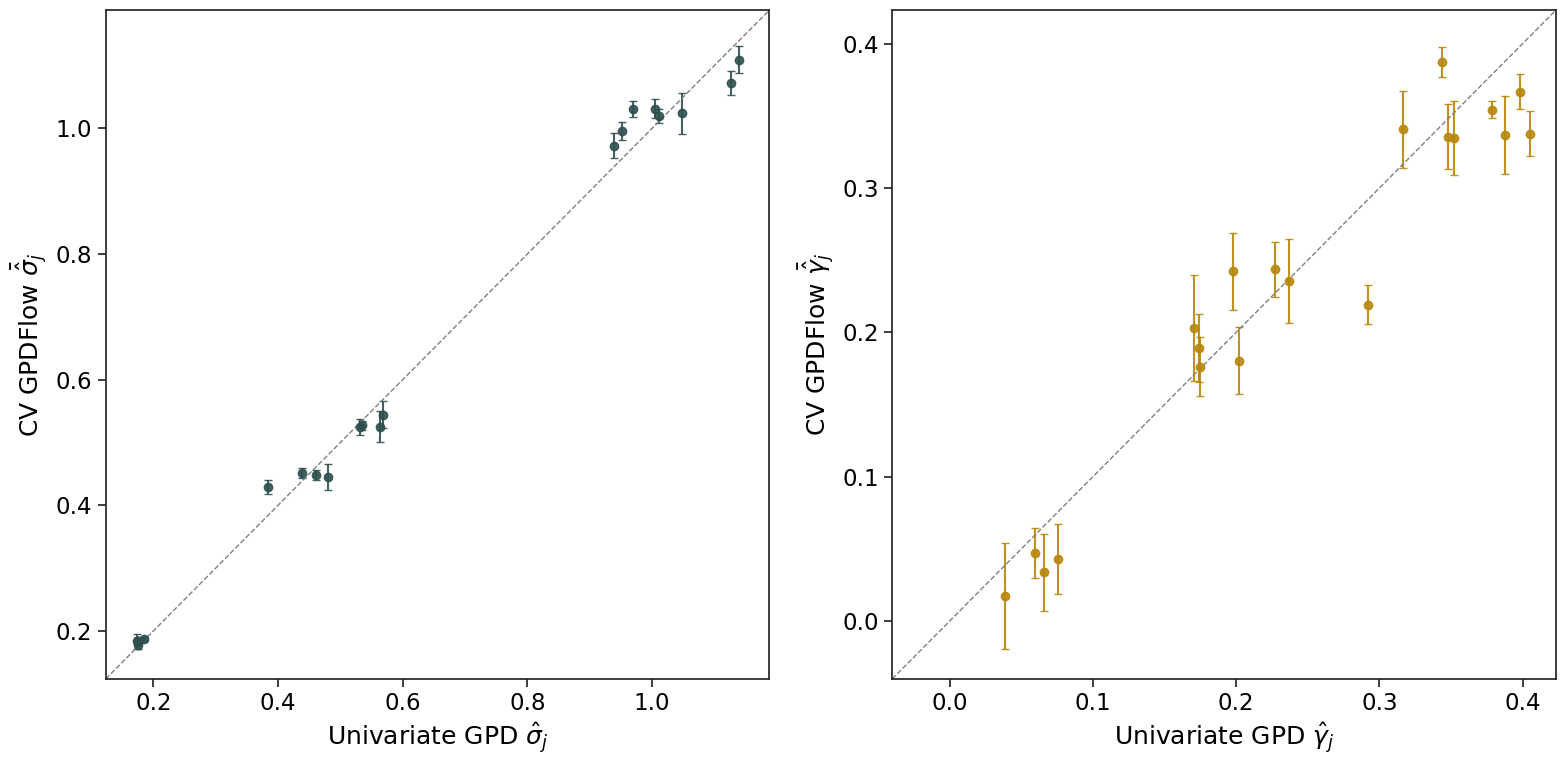

In [11]:
sigma_hat = cv_like['sigma_hat']
gamma_hat = cv_like['gamma_hat']
sigma_hat_folds = cv_like['sigma_hat_folds']
gamma_hat_folds = cv_like['gamma_hat_folds']

uni_sigmas = []
uni_gammas = []
for i in range(dim):
    data_i = samples[samples[:, i] > 0, i]
    c, loc, scale = stats.genpareto.fit(data_i, floc=0)
    uni_gammas.append(c)
    uni_sigmas.append(scale)
uni_sigmas = np.array(uni_sigmas)
uni_gammas = np.array(uni_gammas)

sns.set(style="ticks", font_scale=1.5)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

ax = axes[0]
ax.errorbar(uni_sigmas, sigma_hat, yerr=sigma_hat_folds.std(axis=0),
            fmt='o', color='darkslategray', ecolor='darkslategray',
            alpha=0.9, capsize=3)
lims = [min(*ax.get_xlim(), *ax.get_ylim()), max(*ax.get_xlim(), *ax.get_ylim())]
ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel(r'Univariate GPD $\hat{\sigma}_j$', color='black')
ax.set_ylabel(r'CV GPDFlow $\bar{\hat{\sigma}}_j$', color='black')
ax.tick_params(axis='both', labelcolor='black')

ax = axes[1]
ax.errorbar(uni_gammas, gamma_hat, yerr=gamma_hat_folds.std(axis=0),
            fmt='o', color='darkgoldenrod', ecolor='darkgoldenrod',
            alpha=0.9, capsize=3)
lims = [min(*ax.get_xlim(), *ax.get_ylim()), max(*ax.get_xlim(), *ax.get_ylim())]
ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel(r'Univariate GPD $\hat{\gamma}_j$', color='black')
ax.set_ylabel(r'CV GPDFlow $\bar{\hat{\gamma}}_j$', color='black')
ax.tick_params(axis='both', labelcolor='black')

fig.tight_layout()
plt.show()

p_sim_q          : 0.9920
RMSE chi         : 0.0614
TDE  chi         : 0.0421
mean signed bias : +0.0345


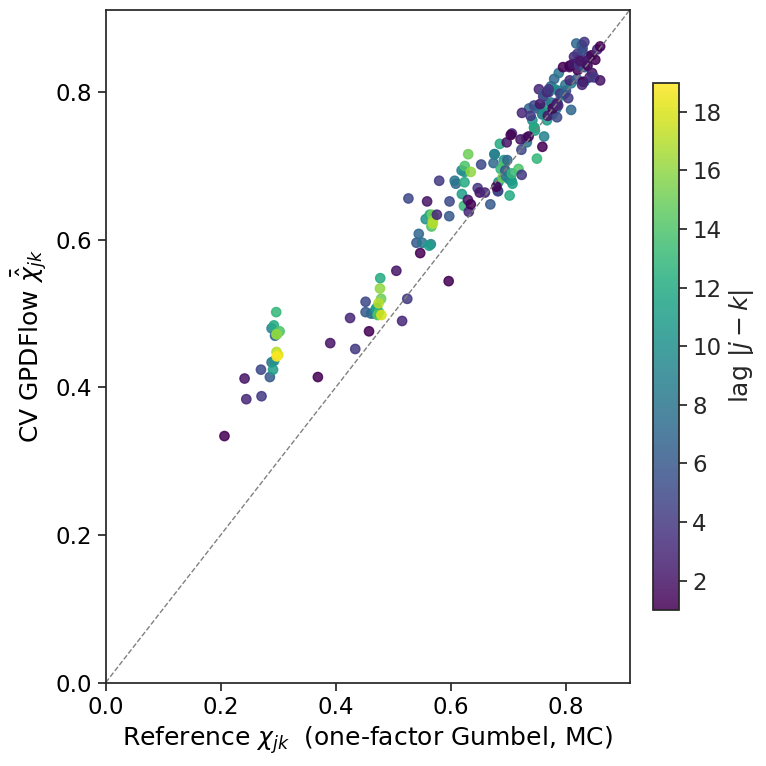

In [12]:
# --- Estimated vs reference pairwise chi -------------------------------------
# Estimated chi = mean over the 5 CV fold models of each fold's rank-based
# pairwise chi of its simulated draws (folds NOT pooled -- a pool of 5 flows is a
# mixture, not an mGPD), evaluated at the cluster-conditional level p_sim_q.
# Reference chi = one-factor Gumbel copula, large-sample MC (cell 5).

chi_hat_mat  = cv_pairwise_chi(cv_like['samples_simu_folds'], p_sim_q)   # (dim, dim)
chi_theo_mat = chi_theo        # one-factor Gumbel, large-sample MC reference (cell 5)

iu = np.triu_indices(dim, k=1)
chi_hat_pairs  = chi_hat_mat[iu]
chi_theo_pairs = chi_theo_mat[iu]
lag_pairs      = iu[1] - iu[0]                                           # |j - k|

print(f'p_sim_q          : {p_sim_q:.4f}')
print(f'RMSE chi         : {cf.rmse_chi(chi_hat_pairs, chi_theo_pairs):.4f}')
print(f'TDE  chi         : {cf.tde_chi(chi_hat_mat, chi_theo_mat):.4f}')
print(f'mean signed bias : {(chi_hat_pairs - chi_theo_pairs).mean():+.4f}')

sns.set(style="ticks", font_scale=1.5)
fig, ax = plt.subplots(figsize=(8, 8))

sc = ax.scatter(chi_theo_pairs, chi_hat_pairs, c=lag_pairs, cmap='viridis',
                alpha=0.85, s=45)
lims = [0.0, max(chi_theo_pairs.max(), chi_hat_pairs.max()) * 1.05]
ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel(r'Reference $\chi_{jk}$  (one-factor Gumbel, MC)', color='black')
ax.set_ylabel(r'CV GPDFlow $\bar{\hat{\chi}}_{jk}$', color='black')
ax.tick_params(axis='both', labelcolor='black')
cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
cb.set_label(r'lag $|j-k|$')

fig.tight_layout()
plt.show()


#### MMD based estimation

In [13]:
# Tuned winner for q = 0.96 from Data_and_Model/sim2s_nsf/best_configs.json["0.96"]["mmd"]
# (CV RMSE chi = 0.0274); non-tuned settings as in tune_threshold_hparams.BASE.
MMD_CFG = dict(
    warmup_epochs=50, min_delta=1e-3,
    penalty_lambda=1e4, mmd_lambda=1, mmd_samples_per_face=128,
    mmd_censor_c=0, mmd_censor_tau=0.2,
    mmd_indicator_alpha=3, mmd_indicator_rho=5,
    num_layers=4, latent_size_factor=2,
    flow_type='nsf', flow_kw=dict(num_bins=3, num_blocks=2, tail_bound=5.0),
    seed=1234,
)

cv_mmd = run_cv_gpdflow_mmd(
    samples, folds, device, thres,
    epochs=EPOCHS_MMD, samples_multiplier=SIM_MULT,
    patience=100, **MMD_CFG,
)
dim_2s = cv_mmd['dim_2s']

print('per-fold best val loss :', np.round(cv_mmd['best_vals'], 4))
print('per-fold best epoch    :', [h['best_epoch'] for h in cv_mmd['hist']])
print('dropped train rows/fold:', cv_mmd['dropped_rows_train'])
print('dropped val rows/fold  :', cv_mmd['dropped_rows_val'])


[mmd] fold 1/5 (train 1004/1004, val 252/252)
  epoch    1/500 | train=0.1944 | val=0.1760
  epoch   25/500 | train=0.0135 | val=0.0135
  epoch   50/500 | train=0.0112 | val=0.0073
  epoch   75/500 | train=0.0048 | val=0.0033
  epoch  100/500 | train=0.0017 | val=0.0034
  epoch  125/500 | train=0.0099 | val=0.0035
  epoch  150/500 | train=0.0029 | val=0.0037
  epoch  175/500 | train=0.0012 | val=0.0095
  epoch  200/500 | train=0.0113 | val=0.0032
  epoch  225/500 | train=-0.0005 | val=0.0044
  epoch  250/500 | train=0.0020 | val=-0.0007
  early stopping at epoch 274 (best val loss @ 174).
[mmd] fold 2/5 (train 1005/1005, val 251/251)
  epoch    1/500 | train=0.2071 | val=0.1455
  epoch   25/500 | train=0.0151 | val=0.0085
  epoch   50/500 | train=0.0106 | val=0.0125
  epoch   75/500 | train=0.0070 | val=0.0087
  epoch  100/500 | train=0.0032 | val=0.0047
  epoch  125/500 | train=0.0116 | val=0.0059
  epoch  150/500 | train=0.0017 | val=0.0053
  epoch  175/500 | train=0.0012 | val=-0.00

p_sim_q          : 0.9920
RMSE chi         : 0.0245
TDE  chi         : 0.0191
mean signed bias : +0.0120


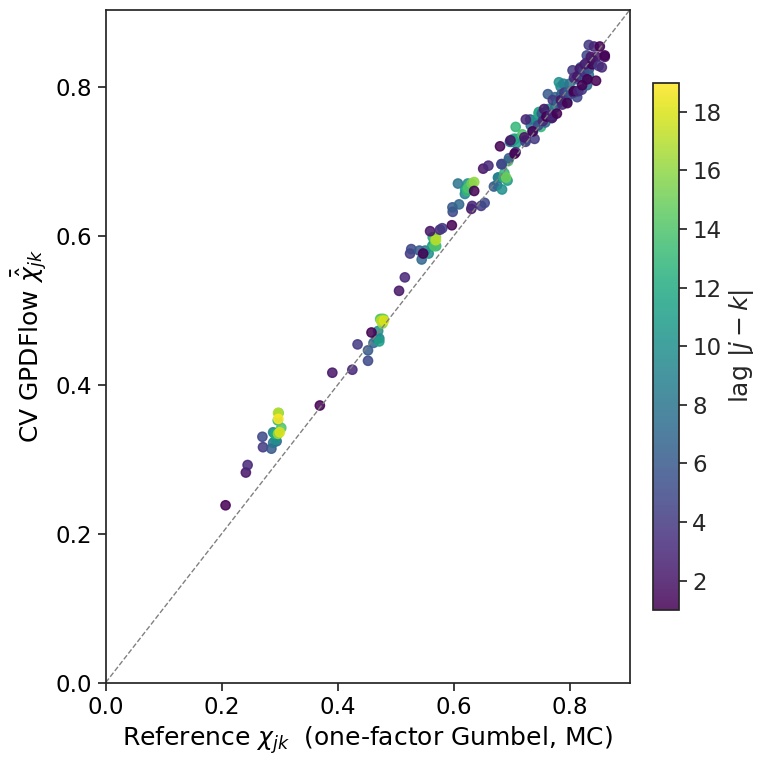

In [14]:
chi_hat_mat  = cv_pairwise_chi(cv_mmd['samples_simu_2s_folds'], p_sim_q)   # (dim, dim)
chi_theo_mat = chi_theo        # one-factor Gumbel, large-sample MC reference (cell 5)

iu = np.triu_indices(dim, k=1)
chi_hat_pairs  = chi_hat_mat[iu]
chi_theo_pairs = chi_theo_mat[iu]
lag_pairs      = iu[1] - iu[0]                                           # |j - k|

print(f'p_sim_q          : {p_sim_q:.4f}')
print(f'RMSE chi         : {cf.rmse_chi(chi_hat_pairs, chi_theo_pairs):.4f}')
print(f'TDE  chi         : {cf.tde_chi(chi_hat_mat, chi_theo_mat):.4f}')
print(f'mean signed bias : {(chi_hat_pairs - chi_theo_pairs).mean():+.4f}')

sns.set(style="ticks", font_scale=1.5)
fig, ax = plt.subplots(figsize=(8, 8))

sc = ax.scatter(chi_theo_pairs, chi_hat_pairs, c=lag_pairs, cmap='viridis',
                alpha=0.85, s=45)
lims = [0.0, max(chi_theo_pairs.max(), chi_hat_pairs.max()) * 1.05]
ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel(r'Reference $\chi_{jk}$  (one-factor Gumbel, MC)', color='black')
ax.set_ylabel(r'CV GPDFlow $\bar{\hat{\chi}}_{jk}$', color='black')
ax.tick_params(axis='both', labelcolor='black')
cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
cb.set_label(r'lag $|j-k|$')

fig.tight_layout()
plt.show()


In [15]:
# Tuned winner for q = 0.96 from Data_and_Model/sim2s_nsf/best_configs.json["0.96"]["bl"]
# (CV RMSE chi = 0.0983).
BL_CFG = dict(warmup=20, seed=0, num_layers=2, hidden_mult=2,
              flow_type='nsf', flow_kw=dict(num_bins=3, num_blocks=2, tail_bound=4.0))

cv_bl = run_cv_flow_baseline(
    samples, folds, device, thres,
    epochs=EPOCHS_BL, samples_multiplier=SIM_MULT,
    patience=40, **BL_CFG,
)
flow_baseline = cv_bl['models'][-1]              # last fold's flow, for the diagnostics below
print('per-fold best val NLL:', np.round(cv_bl['best_vals'], 4))
print('per-fold best epoch  :', [h['best_epoch'] for h in cv_bl['hist']])

[baseline] fold 1/5 (train 1004, val 252)
  epoch    1/500 | train_nll=28.020 | val_nll=27.136
  epoch   25/500 | train_nll=13.613 | val_nll=13.002
  epoch   50/500 | train_nll=10.544 | val_nll=10.190
  epoch   75/500 | train_nll=10.165 | val_nll=9.777
  epoch  100/500 | train_nll=9.947 | val_nll=9.676
  epoch  125/500 | train_nll=9.804 | val_nll=9.570
  epoch  150/500 | train_nll=9.691 | val_nll=9.463
  epoch  175/500 | train_nll=9.668 | val_nll=9.470
  epoch  200/500 | train_nll=9.527 | val_nll=9.439
  epoch  225/500 | train_nll=9.489 | val_nll=9.465
  epoch  250/500 | train_nll=9.507 | val_nll=9.441
  early stopping at epoch 262 (best val NLL @ 222).
[baseline] fold 2/5 (train 1005, val 251)
  epoch    1/500 | train_nll=27.990 | val_nll=27.177
  epoch   25/500 | train_nll=13.368 | val_nll=13.389
  epoch   50/500 | train_nll=10.654 | val_nll=10.621
  epoch   75/500 | train_nll=10.235 | val_nll=10.010
  epoch  100/500 | train_nll=9.959 | val_nll=9.784
  epoch  125/500 | train_nll=9.94

p_sim_q          : 0.9920
RMSE chi         : 0.1013
TDE  chi         : 0.0949
mean signed bias : -0.0944


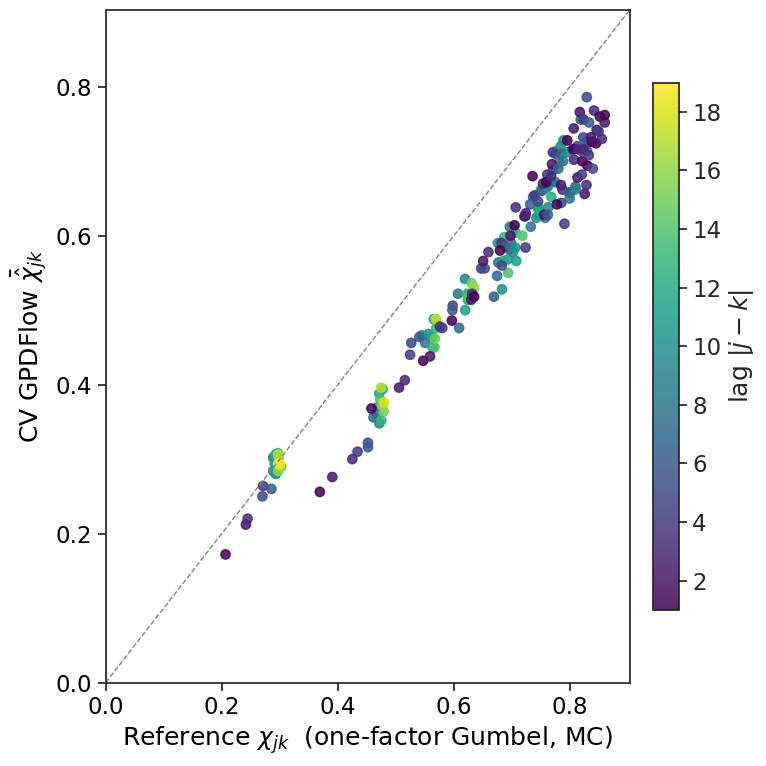

In [16]:
chi_hat_mat  = cv_pairwise_chi(cv_bl['samples_simu_bl_folds'], p_sim_q)   # (dim, dim)
chi_theo_mat = chi_theo        # one-factor Gumbel, large-sample MC reference (cell 5)

iu = np.triu_indices(dim, k=1)
chi_hat_pairs  = chi_hat_mat[iu]
chi_theo_pairs = chi_theo_mat[iu]
lag_pairs      = iu[1] - iu[0]                                           # |j - k|

print(f'p_sim_q          : {p_sim_q:.4f}')
print(f'RMSE chi         : {cf.rmse_chi(chi_hat_pairs, chi_theo_pairs):.4f}')
print(f'TDE  chi         : {cf.tde_chi(chi_hat_mat, chi_theo_mat):.4f}')
print(f'mean signed bias : {(chi_hat_pairs - chi_theo_pairs).mean():+.4f}')

sns.set(style="ticks", font_scale=1.5)
fig, ax = plt.subplots(figsize=(8, 8))

sc = ax.scatter(chi_theo_pairs, chi_hat_pairs, c=lag_pairs, cmap='viridis',
                alpha=0.85, s=45)
lims = [0.0, max(chi_theo_pairs.max(), chi_hat_pairs.max()) * 1.05]
ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel(r'Reference $\chi_{jk}$  (one-factor Gumbel, MC)', color='black')
ax.set_ylabel(r'CV GPDFlow $\bar{\hat{\chi}}_{jk}$', color='black')
ax.tick_params(axis='both', labelcolor='black')
cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
cb.set_label(r'lag $|j-k|$')

fig.tight_layout()
plt.show()


### Parametric mGPD 

In [17]:
import importlib
import parametric_mGPD
importlib.reload(parametric_mGPD)  # pick up edits without a kernel restart
from parametric_mGPD import (
    ParametricMGPD,
    GENERATORS,
    fit_parametric_mgpd,
    support_mask,
)


In [18]:
# Tuned winner for q = 0.96 from Data_and_Model/sim2s_nsf/best_configs.json["0.96"]["par"]
# (CV RMSE chi = 0.0698).
PAR_CFG = dict(generator='log_gamma', seed=1234)

cv_par = run_cv_parametric_mgpd(
    samples, folds, device, thres,
    epochs=EPOCHS_PAR, samples_multiplier=SIM_MULT, **PAR_CFG,
)
print('per-fold best val NLL [par]:', np.round(cv_par['best_vals'], 4))
print('per-fold best epoch   [par]:', [h['best_epoch'] for h in cv_par['hist']])

chi_true_par = cf.pairwise_chi_from_data(samples_origin, p=THRESHOLD_Q)
chi_hat_par_cv = cv_pairwise_chi(cv_par['samples_simu_par_folds'], p_sim_q)
print('Traditional mGPD   tde_chi (CV):',
      round(cf.tde_chi(chi_hat_par_cv, chi_true_par), 4))

[parametric:log_gamma] fold 1/5 (train 1004, val 252)


  [log_gamma ] ep   0  batch loss     13.112   val NLL    13.852   (best    13.852)
  [log_gamma ] ep  50  batch loss      6.808   val NLL     7.507   (best     7.507)
  [log_gamma ] ep 100  batch loss      5.400   val NLL     5.766   (best     5.766)
  [log_gamma ] ep 150  batch loss      4.829   val NLL     5.011   (best     5.011)
  [log_gamma ] ep 200  batch loss      4.609   val NLL     4.611   (best     4.611)
  [log_gamma ] ep 250  batch loss      4.959   val NLL     4.392   (best     4.386)
  [log_gamma ] ep 300  batch loss      4.184   val NLL     4.262   (best     4.260)
  [log_gamma ] ep 350  batch loss      4.278   val NLL     4.174   (best     4.174)
  [log_gamma ] ep 400  batch loss      4.631   val NLL     4.137   (best     4.137)
  [log_gamma ] ep 450  batch loss      4.096   val NLL     4.122   (best     4.122)
  [log_gamma ] ep 499  batch loss      3.976   val NLL     4.121   (best     4.121)
[parametric:log_gamma] fold 2/5 (train 1005, val 251)
  [log_gamma ] ep   0 

p_sim_q          : 0.9920
RMSE chi         : 0.0796
TDE  chi         : 0.0472
mean signed bias : +0.0047


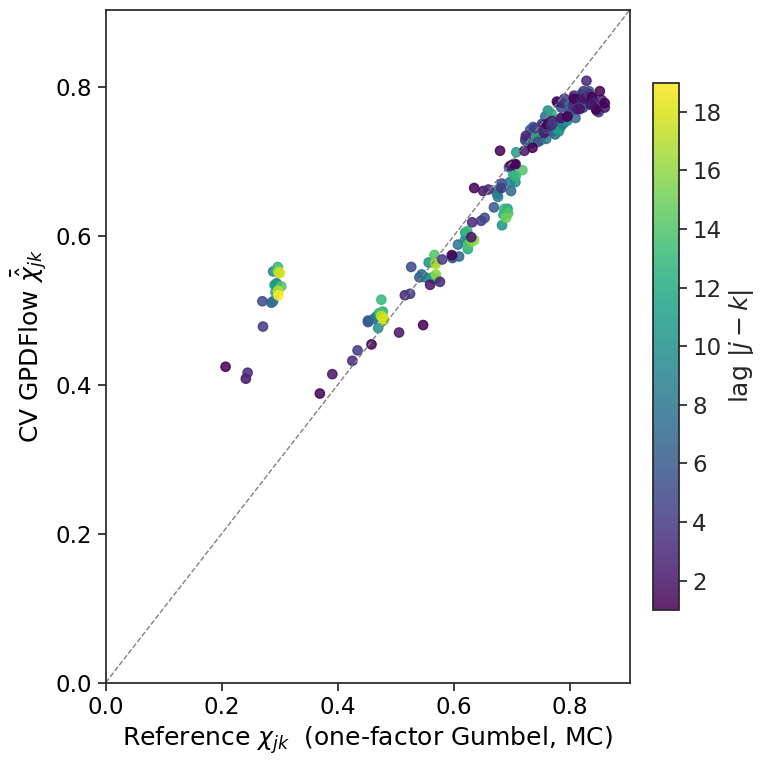

In [19]:
chi_hat_mat  = cv_pairwise_chi(cv_par['samples_simu_par_folds'], p_sim_q)   # (dim, dim)
chi_theo_mat = chi_theo        # one-factor Gumbel, large-sample MC reference (cell 5)

iu = np.triu_indices(dim, k=1)
chi_hat_pairs  = chi_hat_mat[iu]
chi_theo_pairs = chi_theo_mat[iu]
lag_pairs      = iu[1] - iu[0]                                           # |j - k|

print(f'p_sim_q          : {p_sim_q:.4f}')
print(f'RMSE chi         : {cf.rmse_chi(chi_hat_pairs, chi_theo_pairs):.4f}')
print(f'TDE  chi         : {cf.tde_chi(chi_hat_mat, chi_theo_mat):.4f}')
print(f'mean signed bias : {(chi_hat_pairs - chi_theo_pairs).mean():+.4f}')

sns.set(style="ticks", font_scale=1.5)
fig, ax = plt.subplots(figsize=(8, 8))

sc = ax.scatter(chi_theo_pairs, chi_hat_pairs, c=lag_pairs, cmap='viridis',
                alpha=0.85, s=45)
lims = [0.0, max(chi_theo_pairs.max(), chi_hat_pairs.max()) * 1.05]
ax.plot(lims, lims, color='gray', linestyle='--', linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel(r'Reference $\chi_{jk}$  (one-factor Gumbel, MC)', color='black')
ax.set_ylabel(r'CV GPDFlow $\bar{\hat{\chi}}_{jk}$', color='black')
ax.tick_params(axis='both', labelcolor='black')
cb = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
cb.set_label(r'lag $|j-k|$')

fig.tight_layout()
plt.show()


### Far-tail quantities: large-MC "truth" vs the fitted models

For a large fresh **unconditional** Monte-Carlo draw from the DGP (the "true" value) and
for the **cluster-conditional** draws of each fitted model (the "estimated" value,
adjusted to the unconditional scale via the POT/mGPD decomposition,
CLAUDE.md Sec 2.4), compute and compare:

1. marginal quantiles at the `q = 0.9999` level, one per dimension;
2. `P(exactly K_EXCEED of the d components exceed their level-q marginal quantile)`
   as a function of `q`, for a chosen number of simultaneously exceeding
   components `K_EXCEED` (`K_EXCEED = dim` gives "all d components exceed").

Adjustment: a cluster-implied event `A` has `P(A) = p_cluster · P_model(A | cluster)`;
a quantile level `q` asked of the model is read off at `p_sim = 1 − (1−q)/p_cluster`.


In [20]:
# ============================================================================
# Setup: large-MC "truth" sample + shared config for the far-tail quantities
# ============================================================================
Q_SLICE = 0.96          # quantile level that built `samples` / `thres` (cell "dedddfd6").
                        # NB the module-level THRESHOLD_Q was overwritten to 0.999 later on.
N_BIG   = 2_000_000     # raise (e.g. 5_000_000) if the "all d" curve floors out at ~1/N_BIG
Q_MARG  = 0.9999        # marginal-quantile level for quantity 1

p_cluster_fit = samples.shape[0] / samples_origin.shape[0]     # P(exceedance cluster)
p_sim_marg    = 1.0 - (1.0 - Q_MARG) / p_cluster_fit           # model's own-quantile level
assert 0.0 < p_sim_marg < 1.0, p_sim_marg

# Fresh unconditional MC draw from the same one-factor Gumbel + Burr XII DGP as
# cell "229e9ac7" (independent seed).
U_big = simulate_factor_copula(N_BIG, theta, seed=20260908)
cols  = [burr12.ppf(U_big[:, j], c=c_vals[j], d=k_vals[j]).astype(np.float32)
         for j in range(dim)]
del U_big
X_big = np.column_stack(cols)
del cols

thres_row = np.asarray(thres, dtype=float).reshape(-1)         # (dim,)
print(f'X_big {X_big.shape}  |  p_cluster(fit) = {p_cluster_fit:.4f}  '
      f'|  p_cluster(X_big) = {float((X_big > thres_row).any(1).mean()):.4f}')

# A single common *absolute* threshold does not exist here (the Burr XII margins
# have very different tail indices), so quantities 2 & 3 use a per-margin
# threshold vector at a common probability level q: u_j(q) = Q_j(q).  For any
# q >= Q_SLICE, exceeding u_j(q) implies the cluster event, so the SAME u_vec(q)
# serves the truth (directly) and every model (x p_cluster).
#
# q ranges from Q_SLICE (0.96) to 0.999, geometrically dense in the tail
# probability 1 - q so the far tail -- where the joint-exceedance probability
# decays over several orders of magnitude -- is well resolved on a log axis.
Q_GRID = 1.0 - np.geomspace(1.0 - Q_SLICE, 1e-4, 80)           # 0.96 .. 0.999
U_MATS = [np.quantile(X_big, q, axis=0) for q in Q_GRID]       # list of (dim,) vectors

MODELS = [   # (label, per-fold raw-scale draw blocks, colour)
    ('GPDFlow (likelihood)',    cv_like['samples_simu_folds'],    'darkgoldenrod'),
    ('GPDFlow (MMD, two-stage)', cv_mmd['samples_simu_2s_folds'],  'firebrick'),
    ('Probit-copula RealNVP',    cv_bl['samples_simu_bl_folds'],   'steelblue'),
    ('Parametric mGPD',          cv_par['samples_simu_par_folds'], 'seagreen'),
]
TRUTH_C = 'darkslategray'


X_big (2000000, 20)  |  p_cluster(fit) = 0.1256  |  p_cluster(X_big) = 0.1297


In [21]:
# --- helper functions: far-tail quantities, truth + cluster-adjusted model ---
def _finite(X):
    X = np.asarray(X, dtype=float)
    return X[np.isfinite(X).all(axis=1)]


def marginal_quantiles_true(X_big, q):
    """Unconditional marginal q-quantile of every margin -- shape (dim,)."""
    return np.quantile(X_big, q, axis=0)


def marginal_quantiles_model(fold_blocks, p_cluster, q, combine='pool'):
    """Model estimate of the unconditional marginal q-quantile.

    The draws are cluster-conditional, so the unconditional q-quantile equals the
    draws' p_sim-quantile with p_sim = 1 - (1 - q) / p_cluster.
        combine='pool' : one quantile over the 5 fold blocks stacked (needed at
                         q = 0.9999, where a single fold has ~30 draws above p_sim);
        combine='mean' : per-fold quantile, then averaged (folds not pooled).
    Returns (estimate (dim,), per_fold (n_folds, dim) or None).
    """
    p_sim = 1.0 - (1.0 - q) / p_cluster
    if not 0.0 < p_sim < 1.0:
        raise ValueError(f'p_sim={p_sim:.4g} outside (0,1): p_cluster too small for q={q}')
    if combine == 'pool':
        return np.quantile(_finite(np.vstack(fold_blocks)), p_sim, axis=0), None
    per = np.array([np.quantile(_finite(b), p_sim, axis=0) for b in fold_blocks])
    return per.mean(axis=0), per


def prob_all_exceed(X, u_vec):
    """P(all d margins exceed the per-margin threshold vector u_vec)."""
    Xf = _finite(X)
    return cf.simultaneous_exceedance_probability(Xf, u_vec, Xf.shape[1] - 1)


def prob_exactly_k_exceed(X, u_vec, k):
    """P(exactly k of d margins exceed u_vec) = P(#>k-1) - P(#>k)."""
    Xf = _finite(X)
    return (cf.simultaneous_exceedance_probability(Xf, u_vec, k - 1)
            - cf.simultaneous_exceedance_probability(Xf, u_vec, k))


def prob_curve_true(X_big, u_mats, fn):
    """fn evaluated on the large unconditional sample at every u_vec in u_mats."""
    return np.array([fn(X_big, u) for u in u_mats])


def prob_curve_model(fold_blocks, p_cluster, u_mats, fn):
    """Cluster-adjusted model curve: mean over folds of p_cluster * P_model(. | cluster).

    Returns (fold_mean_curve (len(u_mats),), per_fold_curves (n_folds, len(u_mats))).
    """
    per = np.array([[p_cluster * fn(b, u) for u in u_mats] for b in fold_blocks])
    return per.mean(axis=0), per


def max_component_quantile(X, q, p_cluster=1.0):
    """q-quantile of the componentwise maximum  M = max_j X_j.

    p_cluster == 1 : X is an unconditional sample -> plain q-quantile of M.
    p_cluster < 1  : X is cluster-conditional (>=1 margin over its threshold);
                     the unconditional q-quantile of M equals the draws'
                     p_sim-quantile, p_sim = 1 - (1 - q) / p_cluster -- exact
                     while Q_M(q) >= max_j thres_j (there {M > x} => cluster).
    q may be a scalar or an array; the return matches its shape.
    """
    M = _finite(X).max(axis=1)
    p_sim = 1.0 - (1.0 - np.asarray(q, dtype=float)) / p_cluster
    return np.quantile(M, np.clip(p_sim, 0.0, 1.0))


In [22]:
# --- Plot helpers: Simulation_2S_cv_study.ipynb Plot C/D/E style -----------
# Same 2x2 log-ratio layout as cv_study's plot_band_panels (panel order, figure
# size, logit x-axis, shared y-axis, grey ghost lines for the other models,
# panels pinned to Plot A's positions).  Here each model is one fit, so a panel
# shows that model's fold-mean curve only -- no confidence band.
FIGSIZE_A = (10, 10)
TITLE_FS = LABEL_FS = 18
MODELS_A = [MODELS[0], MODELS[1], MODELS[3], MODELS[2]]  # panel order as cv_study Plot A
GHOST_C = '0.6'
Q_TICKS = [0.96, 0.99, 0.999, 0.9999]  # logit-axis major ticks (Q_GRID starts at Q_SLICE)


def _plot_a_panel_positions():
    """Panel positions of cv_study's Plot A (pairwise chi, 2x2 + tight_layout),
    rebuilt on a throwaway figure so these plots share its panel geometry."""
    sns.set(style='ticks', font_scale=1.3)
    fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_A, sharex=True, sharey=True)
    for ax, (label, _, _) in zip(axes.ravel(), MODELS_A):
        ax.plot([0, 1], [0, 1])
        ax.set_title(f'{label}\n' r'$RMSE_\chi$ = 0.000', fontsize=TITLE_FS)
    for i, ax in enumerate(axes.ravel()):
        if i // 2 == 1:
            ax.set_xlabel(r'True $\chi_{ij}$', fontsize=LABEL_FS)
        if i % 2 == 0:
            ax.set_ylabel(r'Model $\hat{\chi}_{ij}$', fontsize=LABEL_FS)
    fig.tight_layout()
    pos = [ax.get_position() for ax in axes.ravel()]
    plt.close(fig)
    return pos


PANEL_POS_A = _plot_a_panel_positions()
TICK_FS = plt.rcParams['xtick.labelsize']

# MC resolution of a model's fold-mean probability: mean over folds of
# p_cluster * (fraction of that fold's draws), so 0 hits -> 0.  Floor at half a
# hit over the pooled draws, as cv_study does per replicate.
PROB_FLOOR = {label: 0.5 * p_cluster_fit / sum(len(b) for b in blocks)
              for label, blocks, _ in MODELS}


def log_ratio_prob(hat, truth, label):
    """log(p_hat / p_true), with p_hat floored at the model's MC resolution."""
    return np.log(np.maximum(hat, PROB_FLOOR[label]) / truth)


def report_floor(hats):
    """Fraction of q-grid points with 0 simulated hits, per model."""
    for label, _, _ in MODELS:
        print(f'  {label:24s} zero-hit fraction = {np.mean(hats[label] < PROB_FLOOR[label]):.3f}')


def _layout_like_plot_a(fig, axes, ylabel, pad_pt=4):
    """Pin the 2x2 axes to Plot A's panel positions (no tight_layout, which
    would resize the panels around the long y label).  One y label is
    centred on the left column, pad_pt from its tick labels."""
    for ax, pos in zip(axes.ravel(), PANEL_POS_A):
        ax.set_position(pos)
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    left = min(ax.yaxis.get_tightbbox(r).x0 for ax in axes[:, 0])
    y_mid = (axes[1, 0].get_position().y0 + axes[0, 0].get_position().y1) / 2
    fig.supylabel(ylabel, color='black', fontsize=LABEL_FS, ha='right',
                  x=(left - pad_pt / 72 * fig.dpi) / fig.bbox.width, y=y_mid)


def plot_curve_panels(curves, x, ylabel, xlabel='q', xscale='logit', pad=0.08):
    """2x2 small multiples of one curve per model on the plotted scale.

    curves: {model label: 1-D array over x}.  Panel = that model's curve;
    other models' curves as grey ghosts; 0 reference line.  All panels share
    one y-axis.  Title RMSE = root mean square of the curve over x.
    """
    sns.set(style='ticks', font_scale=1.3)
    ymin = min(0.0, min(np.min(c) for c in curves.values()))
    ymax = max(0.0, max(np.max(c) for c in curves.values()))
    span = ymax - ymin

    fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_A, sharex=True, sharey=True)
    for ax, (label, _, color) in zip(axes.ravel(), MODELS_A):
        for l2, _, _ in MODELS_A:
            if l2 != label:
                ax.plot(x, curves[l2], color=GHOST_C, linewidth=1, zorder=1)
        c = curves[label]
        rmse = np.sqrt(np.mean(c ** 2))
        ax.plot(x, c, color=color, linewidth=2.2, zorder=3)
        ax.axhline(0, color='gray', linestyle='--', linewidth=1, zorder=0)
        ax.set_xscale(xscale)
        if xscale == 'logit':
            ax.set_xticks(Q_TICKS, [str(t) for t in Q_TICKS])
            ax.xaxis.set_minor_formatter(plt.NullFormatter())
        ax.set_title(f'{label}\nRMSE = {rmse:.3f}', color='black', fontsize=TITLE_FS)
        ax.tick_params(axis='both', which='both', labelcolor='black',
                       labelsize=TICK_FS)
    axes[0, 0].set_ylim(ymin - pad * span, ymax + pad * span)
    for ax in axes[1]:
        ax.set_xlabel(xlabel, color='black', fontsize=LABEL_FS)
    _layout_like_plot_a(fig, axes, ylabel)
    plt.show()

marginal q = 0.9999 quantile   |   RMSE(log scale) vs truth
  GPDFlow (likelihood)     : 0.1738
  GPDFlow (MMD, two-stage) : 0.1393
  Probit-copula RealNVP    : 0.1141
  Parametric mGPD          : 0.4326


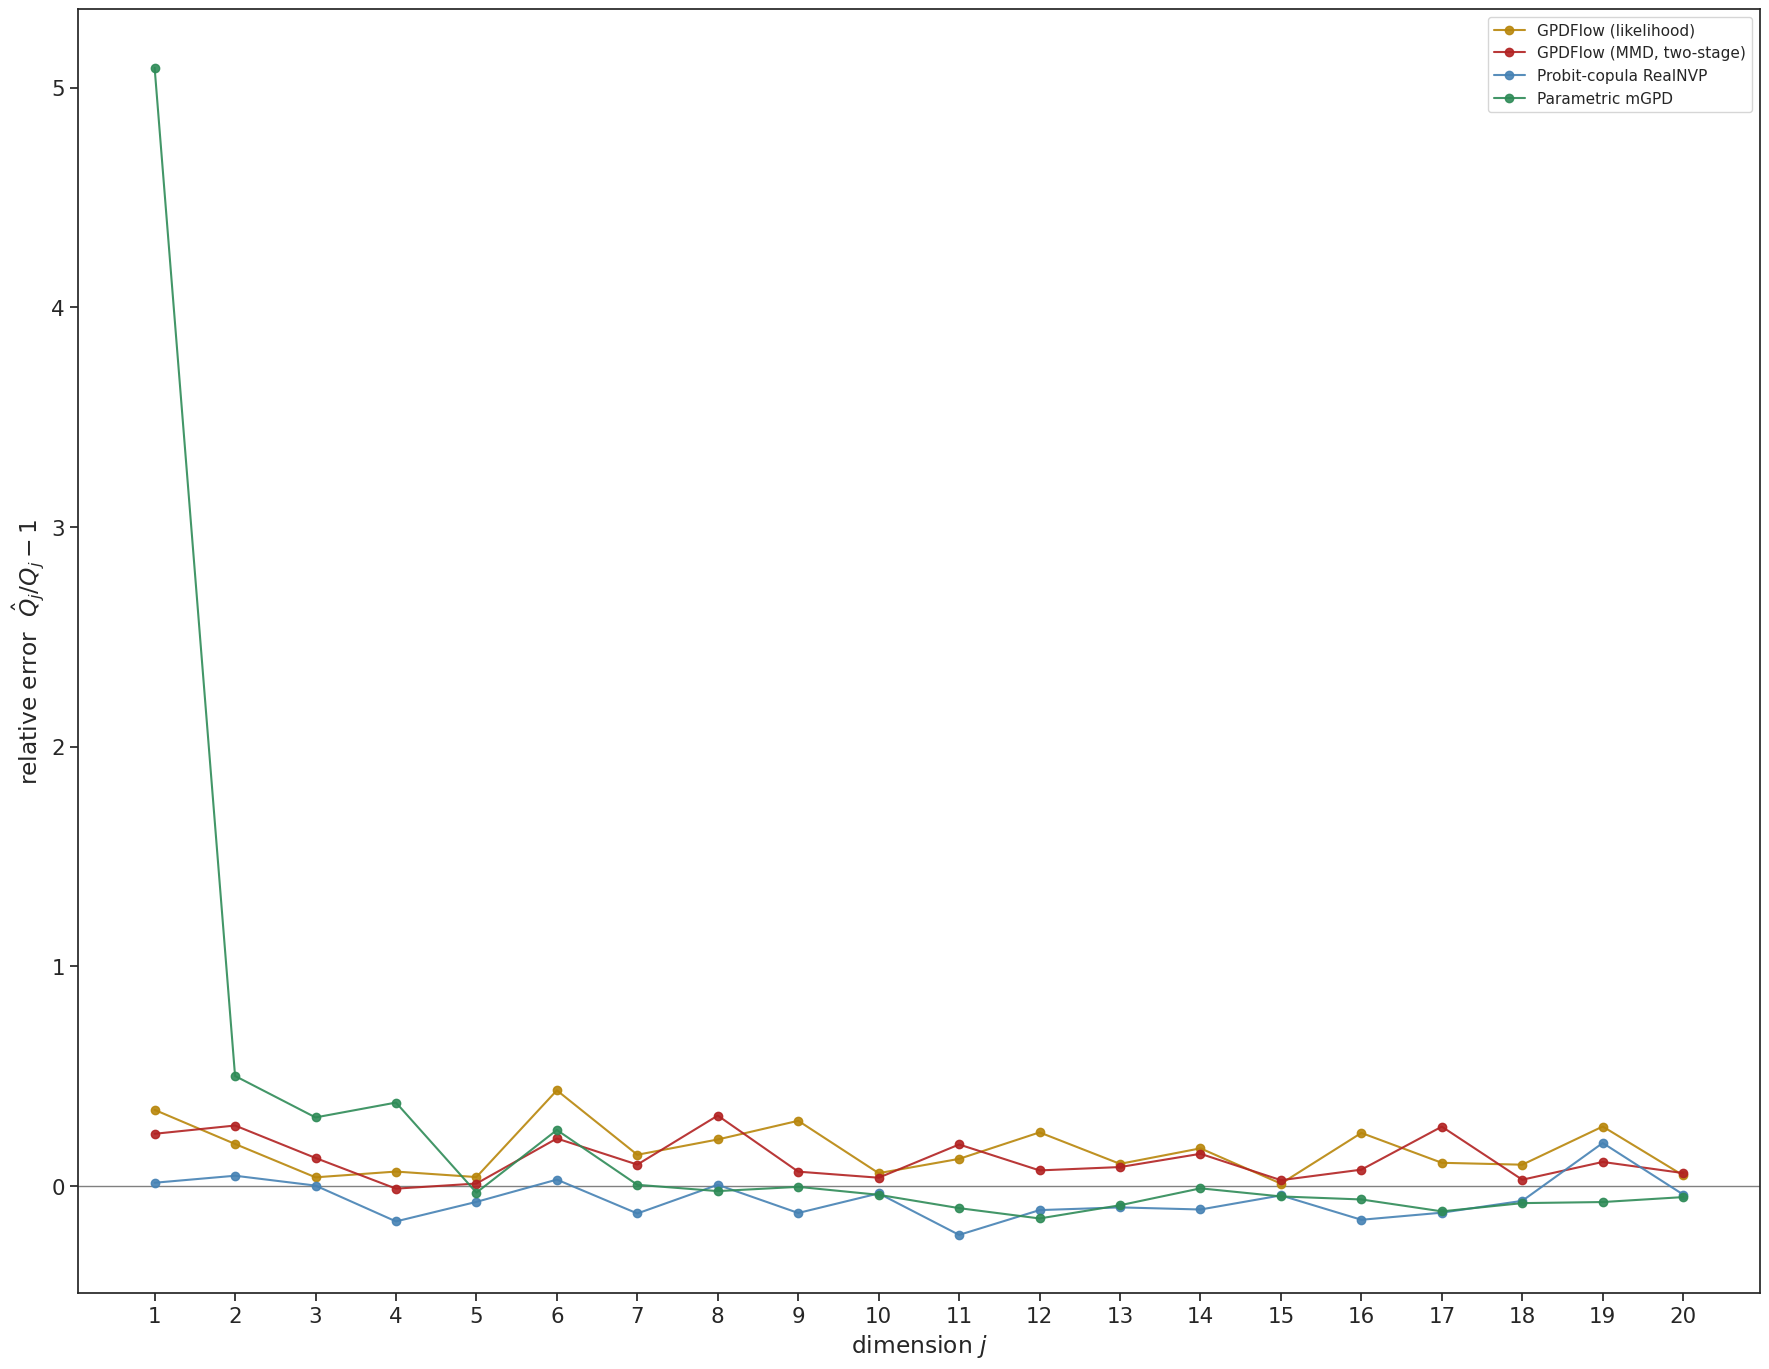

In [23]:
# --- Quantity 1: marginal quantiles at q = 0.9999, all dimensions -----------
q_true = marginal_quantiles_true(X_big, Q_MARG)

dims_ax = np.arange(1, dim + 1)
model_q = []
print(f'marginal q = {Q_MARG} quantile   |   RMSE(log scale) vs truth')
for label, blocks, color in MODELS:
    q_hat, _ = marginal_quantiles_model(blocks, p_cluster_fit, Q_MARG, combine='pool')
    model_q.append((label, q_hat, color))
    print(f'  {label:24s} : {cf.rmse_log_sigma(q_hat, q_true):.4f}')

sns.set(style='ticks', font_scale=1.4)
fig, axes = plt.subplots(1, 1, figsize=(18, 14))

# ax = axes[0]
# ax.plot(dims_ax, q_true, '-o', color=TRUTH_C, lw=2, label='Truth (large MC)')
# for label, q_hat, color in model_q:
#     ax.plot(dims_ax, q_hat, 'o', color=color, alpha=0.9, label=label)
# ax.set_yscale('log')
# ax.set_xlabel('dimension $j$')
# ax.set_ylabel(rf'marginal ${Q_MARG}$ quantile  $Q_j({Q_MARG})$')
# ax.set_xticks(dims_ax)
# ax.legend(fontsize=11)

ax = axes
ax.axhline(0.0, color='gray', lw=1)
for label, q_hat, color in model_q:
    ax.plot(dims_ax, q_hat / q_true - 1.0, 'o-', color=color, alpha=0.9, label=label)
ax.set_xlabel('dimension $j$')
ax.set_ylabel(r'relative error  $\hat Q_j / Q_j - 1$')
ax.set_xticks(dims_ax)
ax.legend(fontsize=11)

fig.tight_layout()
plt.show()


P(exactly 10 of 20 exceed):
  model                         LJPE   RMSLE_p   (over q where truth > 0)
  GPDFlow (likelihood)        0.3982    0.4805
  GPDFlow (MMD, two-stage)    0.3050    0.3597
  Probit-copula RealNVP       0.4182    0.5073
  Parametric mGPD             0.4122    1.8015
  GPDFlow (likelihood)     zero-hit fraction = 0.000
  GPDFlow (MMD, two-stage) zero-hit fraction = 0.000
  Probit-copula RealNVP    zero-hit fraction = 0.000
  Parametric mGPD          zero-hit fraction = 0.013


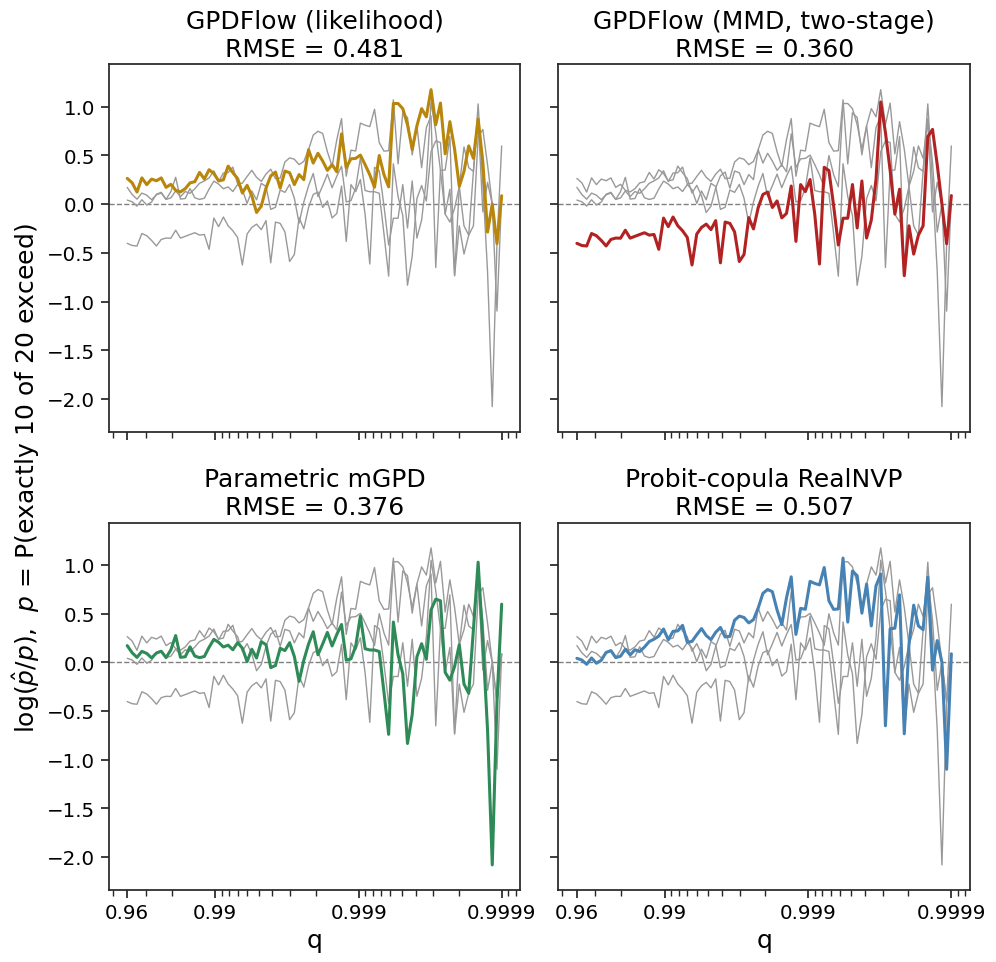

In [28]:
# --- Quantities 2 & 3: count-exceedance probability vs level q -------------
# P(exactly K_EXCEED of the d margins exceed their common-level threshold Q_j(q))
# as a function of q.  u_vec(q) = per-margin q-quantile of X_big; the SAME vector
# serves the truth (empirical probability) and every model (x p_cluster).
# Set K_EXCEED to the number of simultaneously exceeding components you want to
# see; K_EXCEED == dim is the "all d components exceed" case.
K_EXCEED = 10

fn_k = lambda X, u: prob_exactly_k_exceed(X, u, K_EXCEED)
tail = 'all d' if K_EXCEED == dim else f'exactly {K_EXCEED}'

p_k_true = prob_curve_true(X_big, U_MATS, fn_k)

curves = {}          # label -> dict(color, mean, per_fold)
for label, blocks, color in MODELS:
    mean_curve, per_fold = prob_curve_model(blocks, p_cluster_fit, U_MATS, fn_k)
    curves[label] = dict(color=color, mean=mean_curve, per_fold=per_fold)

ok = p_k_true > 0
print(f'P({tail} of {dim} exceed):')
print(f'  {"model":24s} {"LJPE":>9s} {"RMSLE_p":>9s}   (over q where truth > 0)')
for label, d in curves.items():
    print(f'  {label:24s} {cf.ljpe(d["mean"][ok], p_k_true[ok]):9.4f} '
          f'{cf.rmsle_p(d["mean"][ok], p_k_true[ok]):9.4f}')
report_floor({label: d['mean'][ok] for label, d in curves.items()})

# cv_study Plot C style: log(p_hat / p) in a 2x2 grid (fold-mean curve, no band)
plot_curve_panels({label: log_ratio_prob(d['mean'][ok], p_k_true[ok], label)
                   for label, d in curves.items()},
                  Q_GRID[ok],
                  rf'$\log(\hat p / p)$,  $p$ = P({tail} of {dim} exceed)')

quantile of M = max_j X_j   |   RMSE(log scale) vs empirical, q in [0.960, 1.000]
  GPDFlow (likelihood)     : 0.0995
  GPDFlow (MMD, two-stage) : 0.1133
  Probit-copula RealNVP    : 0.1072
  Parametric mGPD          : 0.6855


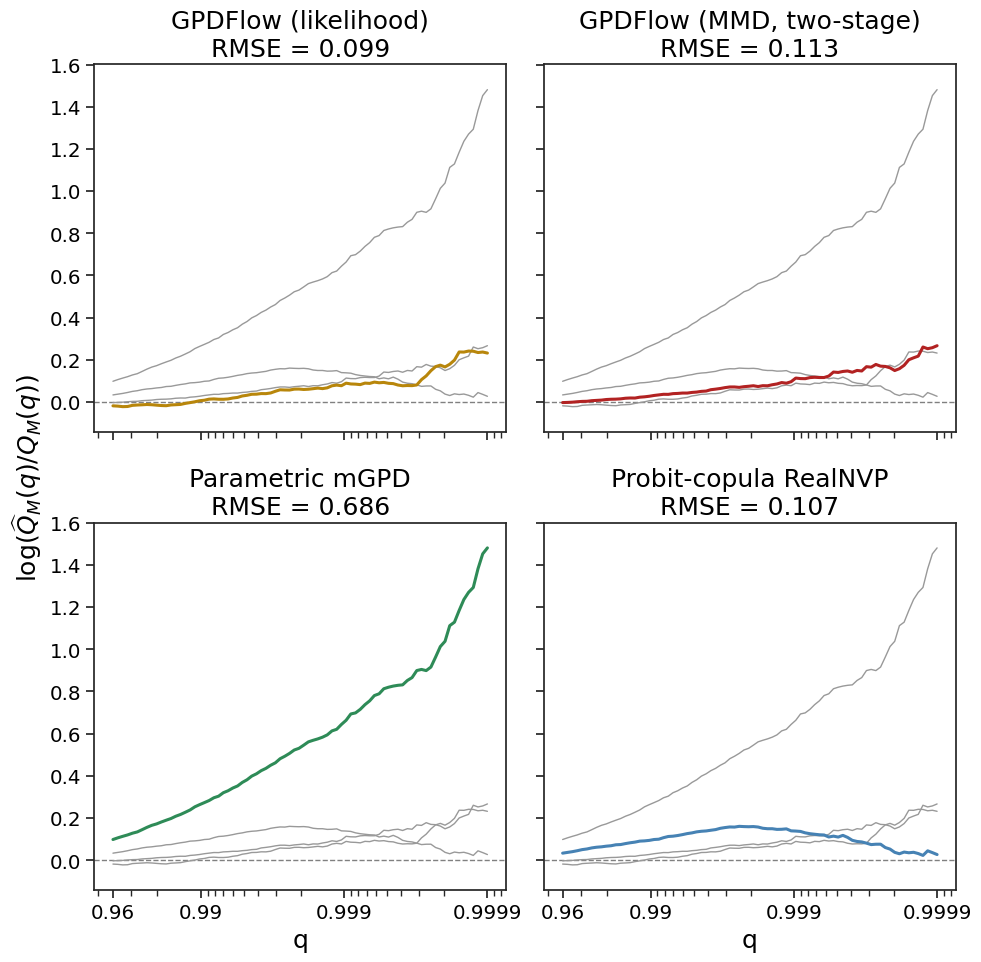

In [25]:
# --- Quantile of the componentwise maximum  M = max_j X_j  vs level q ------
# Empirical : unconditional q-quantile of M from the large MC sample.
# Model     : pooled cluster-conditional draws read at p_sim = 1-(1-q)/p_cluster
#             (exact here -- Q_M(q) >= max_j thres_j across the whole q grid,
#             since the 0.96 quantile of a 20-way max already sits above every
#             margin's 0.96 quantile).
qm_true   = max_component_quantile(X_big, Q_GRID)
qm_models = [(label, max_component_quantile(np.vstack(blocks), Q_GRID, p_cluster_fit), color)
             for label, blocks, color in MODELS]

print(f'quantile of M = max_j X_j   |   RMSE(log scale) vs empirical, '
      f'q in [{Q_GRID.min():.3f}, {Q_GRID.max():.3f}]')
for label, qm_hat, _ in qm_models:
    print(f'  {label:24s} : {cf.rmse_log_sigma(qm_hat, qm_true):.4f}')

# cv_study Plot D style: log(Q_M_hat / Q_M) in a 2x2 grid (no band)
plot_curve_panels({label: np.log(qm_hat / qm_true) for label, qm_hat, _ in qm_models},
                  Q_GRID, r'$\log(\widehat Q_M(q) / Q_M(q))$')

P(X_j > Q_j(q), j in {1,2,3,4,5}):
  model                         LJPE   RMSLE_p   (over q where truth > 0)
  GPDFlow (likelihood)        0.6943    0.7569
  GPDFlow (MMD, two-stage)    0.2337    0.2614
  Probit-copula RealNVP       1.8259    4.9057
  Parametric mGPD             0.6550    0.6770
  GPDFlow (likelihood)     zero-hit fraction = 0.000
  GPDFlow (MMD, two-stage) zero-hit fraction = 0.000
  Probit-copula RealNVP    zero-hit fraction = 0.087
  Parametric mGPD          zero-hit fraction = 0.000


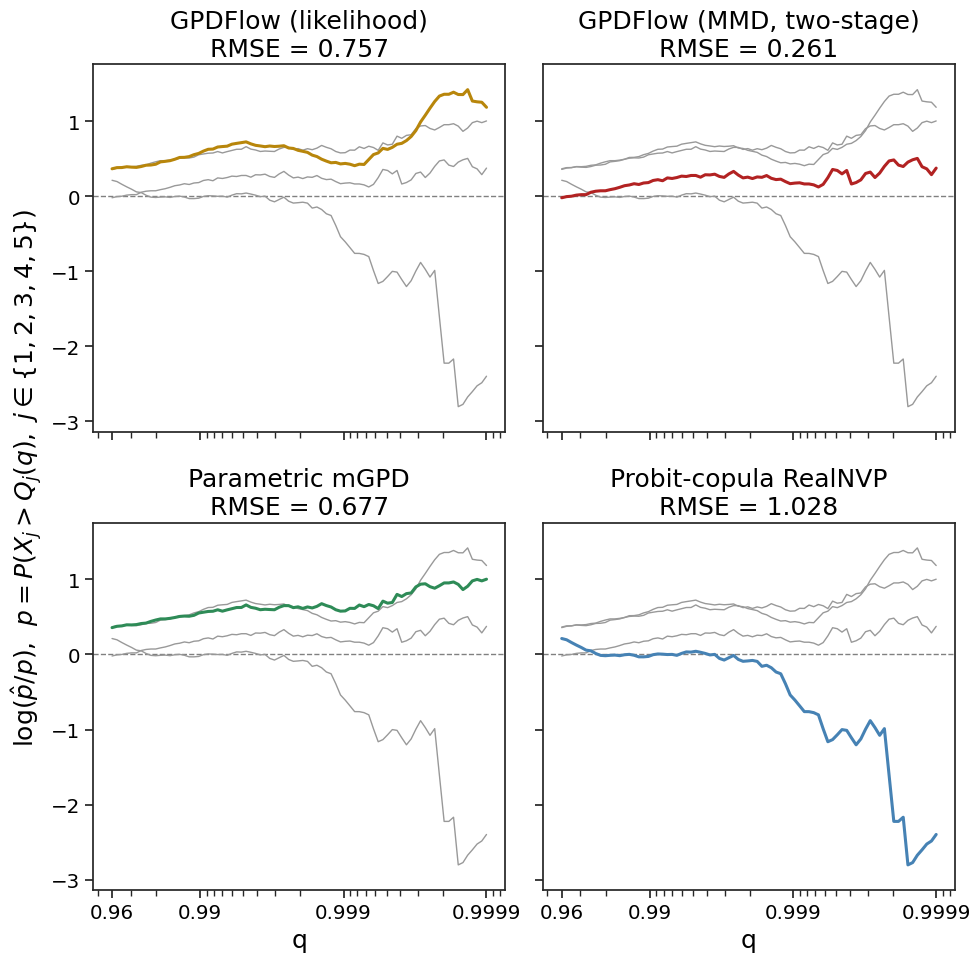

P(X_j > Q_j(q), j in {16,17,18,19,20}):
  model                         LJPE   RMSLE_p   (over q where truth > 0)
  GPDFlow (likelihood)        0.3087    0.3261
  GPDFlow (MMD, two-stage)    0.2002    0.2257
  Probit-copula RealNVP       0.2256    0.3908
  Parametric mGPD             0.4241    0.4298
  GPDFlow (likelihood)     zero-hit fraction = 0.000
  GPDFlow (MMD, two-stage) zero-hit fraction = 0.000
  Probit-copula RealNVP    zero-hit fraction = 0.000
  Parametric mGPD          zero-hit fraction = 0.000


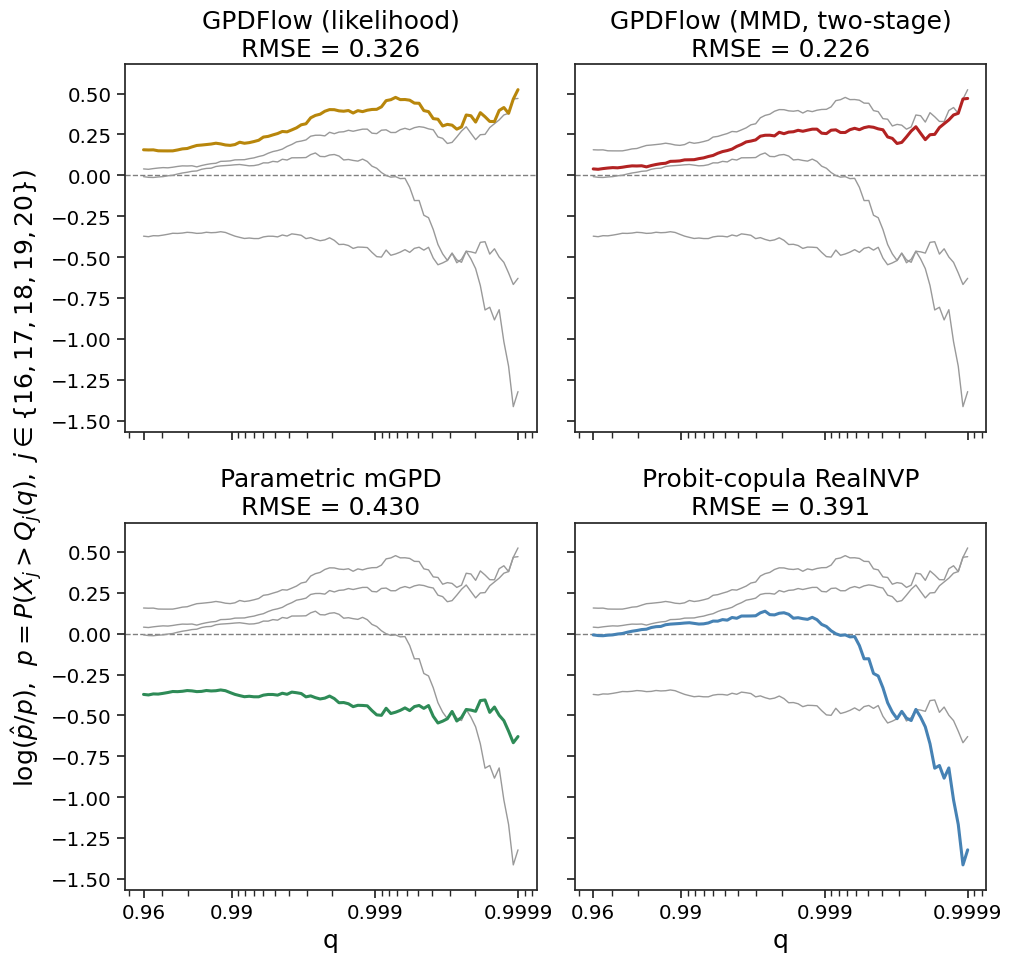

In [ ]:
# --- Joint exceedance probability for a chosen subset of components --------
# P(X_j > Q_j(q) for all j in comp_idx) as a function of q.  Q_j(q) = per-margin
# q-quantile of X_big; truth = empirical on X_big, models = p_cluster x
# cluster-conditional probability (mean over folds).
# Valid for q >= Q_SLICE: any X_j > Q_j(q) >= thres_j implies the cluster event.

def prob_joint_exceed(X, u_vec, comp_idx):
    """P(X_j > u_j for every j in comp_idx)."""
    Xf = _finite(X)
    idx = np.asarray(comp_idx, dtype=int)
    return np.mean(np.all(Xf[:, idx] > np.asarray(u_vec)[idx], axis=1))


def plot_joint_exceedance(comp_idx, q_grid=Q_GRID, models=MODELS):
    """Compute + plot truth vs model joint exceedance curves for components
    `comp_idx` (0-based column indices; shown 1-based in labels).
    Returns dict(q=..., truth=..., models={label: (mean, per_fold)})."""
    comp_idx = np.atleast_1d(np.asarray(comp_idx, dtype=int))
    assert comp_idx.min() >= 0 and comp_idx.max() < dim, comp_idx
    assert len(set(comp_idx.tolist())) == len(comp_idx), 'duplicate component index'
    u_mats = U_MATS if q_grid is Q_GRID else [np.quantile(X_big, q, axis=0) for q in q_grid]
    fn = lambda X, u: prob_joint_exceed(X, u, comp_idx)

    p_true = prob_curve_true(X_big, u_mats, fn)
    res = {label: prob_curve_model(blocks, p_cluster_fit, u_mats, fn) + (color,)
           for label, blocks, color in models}

    # metrics over q where truth > 0 (same as cell 27)
    comp_str = ','.join(str(j + 1) for j in comp_idx)
    ok = p_true > 0
    print(f'P(X_j > Q_j(q), j in {{{comp_str}}}):')
    print(f'  {"model":24s} {"LJPE":>9s} {"RMSLE_p":>9s}   (over q where truth > 0)')
    for label, (mean, _, _) in res.items():
        print(f'  {label:24s} {cf.ljpe(mean[ok], p_true[ok]):9.4f} '
              f'{cf.rmsle_p(mean[ok], p_true[ok]):9.4f}')
    report_floor({label: mean[ok] for label, (mean, _, _) in res.items()})

    # cv_study Plot E style: log(p_hat / p) in a 2x2 grid (fold-mean curve, no band)
    plot_curve_panels({label: log_ratio_prob(mean[ok], p_true[ok], label)
                       for label, (mean, _, _) in res.items()},
                      np.asarray(q_grid)[ok],
                      rf'$\log(\hat p / p)$,  $p = P(X_j > Q_j(q),\ j \in \{{{comp_str}\}})$')
    return dict(q=np.asarray(q_grid), truth=p_true,
                models={k: (v[0], v[1]) for k, v in res.items()})


# examples: weakly vs strongly dependent components (theta increases with j)
jp_low  = plot_joint_exceedance([0, 1, 2, 3, 4])
jp_high = plot_joint_exceedance([dim - 5, dim - 4, dim - 3, dim - 2, dim - 1,
                                 ])

P(X_j > Q_j(q), j in {1,2,3,4,5,6,7,8,9,10}):
  model                         LJPE   RMSLE_p   (over q where truth > 0)
  GPDFlow (likelihood)        0.7182    0.7906
  GPDFlow (MMD, two-stage)    0.2375    0.2747
  Probit-copula RealNVP       2.5904    6.1291
  Parametric mGPD             0.4378    0.4591
  GPDFlow (likelihood)     zero-hit fraction = 0.000
  GPDFlow (MMD, two-stage) zero-hit fraction = 0.000
  Probit-copula RealNVP    zero-hit fraction = 0.138
  Parametric mGPD          zero-hit fraction = 0.000


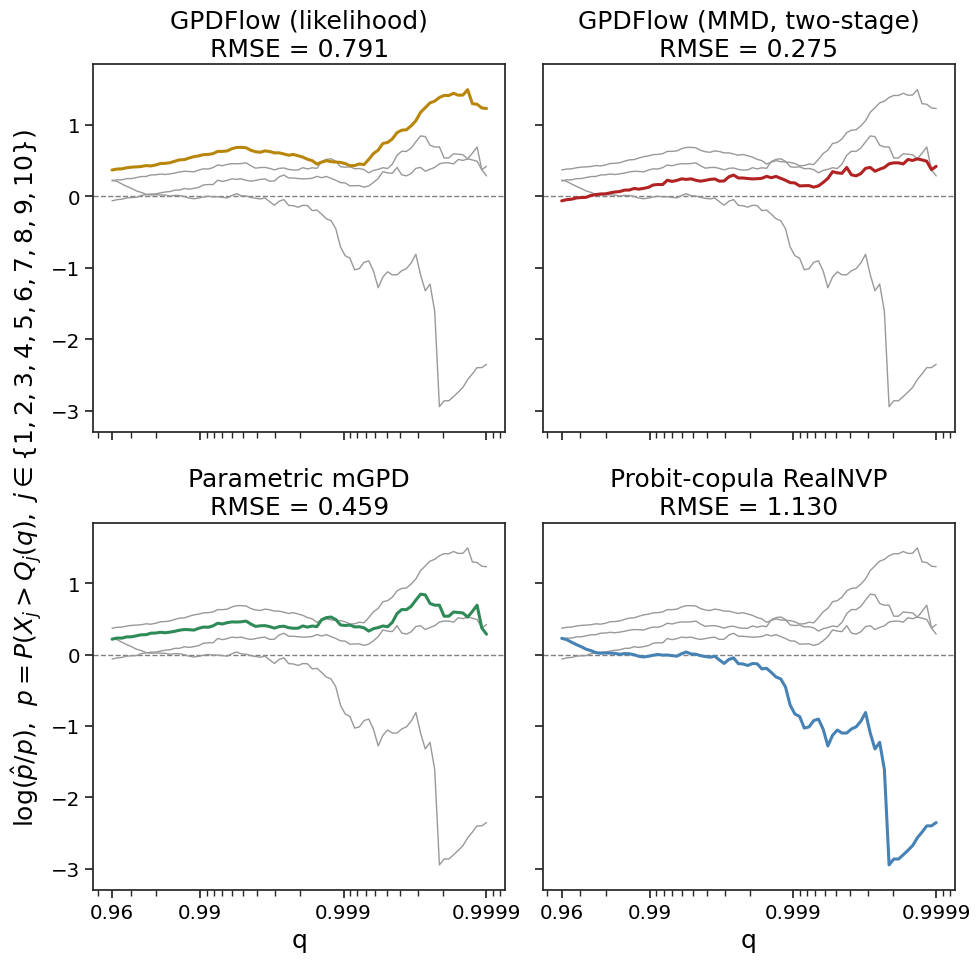

P(X_j > Q_j(q), j in {11,12,13,14,15,16,17,18,19,20}):
  model                         LJPE   RMSLE_p   (over q where truth > 0)
  GPDFlow (likelihood)        0.3041    0.3213
  GPDFlow (MMD, two-stage)    0.1871    0.2147
  Probit-copula RealNVP       0.4440    0.9099
  Parametric mGPD             0.3982    0.4052
  GPDFlow (likelihood)     zero-hit fraction = 0.000
  GPDFlow (MMD, two-stage) zero-hit fraction = 0.000
  Probit-copula RealNVP    zero-hit fraction = 0.000
  Parametric mGPD          zero-hit fraction = 0.000


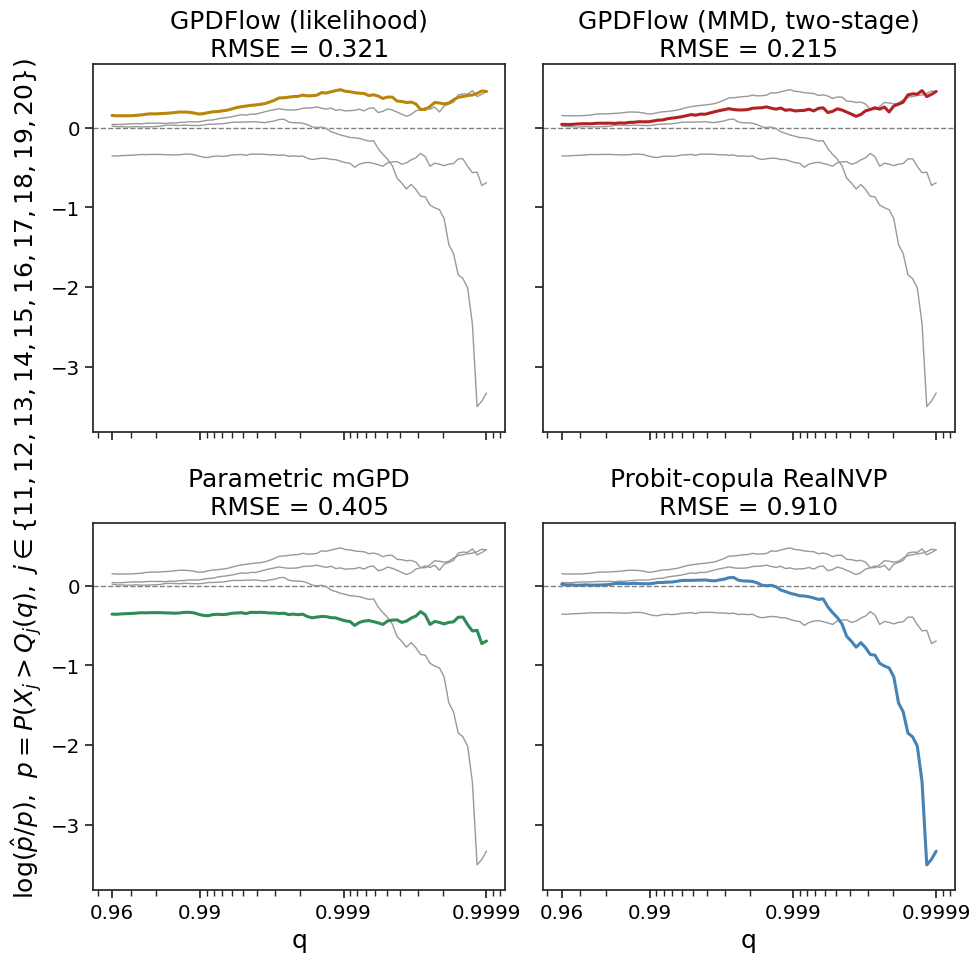

In [27]:
jp_low  = plot_joint_exceedance([0, 1, 2, 3, 4,
                                 5, 6, 7, 8, 9])
jp_high = plot_joint_exceedance([
    dim - 10, dim - 9, dim - 8, dim - 7, dim - 6,
    dim - 5, dim - 4, dim - 3, dim - 2, dim - 1,
                                 ])